# 07 - Stylometric features on HC3

The 14 stylometric features that augment DistilBERT's classifier
head (§3.3) are checked here before they are computed over MAGE. HC3 is the
development corpus, so this is where features are evaluated and fixed; MAGE is
only used for the reported results (§3.2).

This notebook seeks to answer the following questions:

1. Do the features separate human from ChatGPT text at all? A feature that
   cannot tell the classes apart on a simple corpus is unlikely to help on
   MAGE, and is a candidate for cutting.
2. Does any feature measure text length? §3.2 excludes length deliberately,
   because it separates the classes through how the data were collected rather
   than who wrote them. MATTR exists in place of the plain type-token ratio for
   exactly this reason, so this check is whether that worked.
3. How much do the features duplicate each other? Three pairs overlap by
   construction, and §3.5 computes SHAP importances over these features for
   RQ3. SHAP divides credit between correlated inputs, so duplication adds noise
   to U_k without adding signal.
4. Does MATTR have enough spread at a 25-word window? The window was set to 25
   because a larger one sends too many short texts down the fallback branch, but
   Covington and McFall's relation suggests the measure saturates below about 32
   words. If it does, the feature cannot discriminate.

The validation split is used rather than the training split, because it keeps
its natural lengths and question two is about length.

## 1. Compute the features

The same three lines as notebook 02, so this is the identical split the lexical
baseline was measured on.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from logos.paths import DATA_DIR
from logos.project_data.hc3 import load_hc3, clean_hc3
from logos.project_data.preprocess import preprocess, train_val_split
from logos.features.stylometric import FEATURE_NAMES, features_frame

LABELS = {0: "human", 1: "chatgpt"}

hc3 = preprocess(clean_hc3(load_hc3()))
_, val_df = train_val_split(hc3, val_fraction=0.15)

print("validation split:", val_df.shape)
print(val_df["label"].map(LABELS).value_counts().to_dict())

validation split: (11708, 6)
{'human': 7785, 'chatgpt': 3923}


In [2]:
features = features_frame(val_df["text"].tolist(), show_progress=True)

features = features.assign(
    label=val_df["label"].to_numpy(),
    domain=val_df["domain"].to_numpy(),
    words=val_df["text"].str.split().str.len().to_numpy(),
)

print(features.shape)
features[FEATURE_NAMES].describe().T.round(3)

  1,000 of 11,708
  2,000 of 11,708
  3,000 of 11,708
  4,000 of 11,708
  5,000 of 11,708
  6,000 of 11,708
  7,000 of 11,708
  8,000 of 11,708
  9,000 of 11,708
  10,000 of 11,708
  11,000 of 11,708
(11708, 17)


,count,mean,std,min,25%,50%,75%,max
sentence_length_mean,11708.0,21.637,10.081,0.000,15.571,20.000,25.167,179.000
sentence_length_sd,11708.0,8.134,6.629,0.000,4.549,7.199,10.280,85.500
mattr,11708.0,0.876,0.053,0.000,0.849,0.879,0.906,1.000
hapax_rate,11708.0,0.730,0.118,0.000,0.648,0.721,0.808,1.000
stopword_rate,11708.0,0.479,0.063,0.000,0.445,0.483,0.519,0.758
punctuation_rate,11708.0,0.028,0.014,0.000,0.019,0.025,0.033,0.424
noun_rate,11708.0,0.259,0.070,0.000,0.215,0.253,0.295,0.750
verb_rate,11708.0,0.184,0.044,0.000,0.158,0.183,0.209,0.500
past_tense_rate,11708.0,0.035,0.034,0.000,0.012,0.027,0.048,0.333
adverb_rate,11708.0,0.059,0.038,0.000,0.033,0.054,0.078,0.385


## 2. Do the features separate the classes?

Each feature is on its own scale, so comparing raw differences between the
classes would say more about the scales than the features. Cohen's d divides the
difference in means by the pooled standard deviation, which makes the features
comparable: roughly, 0.2 is a small difference, 0.5 moderate and 0.8 large.

The sign says which way it goes. Positive means ChatGPT text scores higher.

In [3]:
def cohens_d(values, labels):
    human = values[labels == 0]
    machine = values[labels == 1]
    pooled = np.sqrt((human.var(ddof=1) + machine.var(ddof=1)) / 2)

    if pooled == 0:
        return 0.0

    return (machine.mean() - human.mean()) / pooled


labels = features["label"].to_numpy()

separation = pd.DataFrame({
    "human_mean": [features.loc[labels == 0, f].mean() for f in FEATURE_NAMES],
    "chatgpt_mean": [features.loc[labels == 1, f].mean() for f in FEATURE_NAMES],
    "d": [cohens_d(features[f].to_numpy(), labels) for f in FEATURE_NAMES],
}, index=FEATURE_NAMES)

separation["abs_d"] = separation["d"].abs()
separation.sort_values("abs_d", ascending=False).round(3)

,human_mean,chatgpt_mean,d,abs_d
hapax_rate,0.773,0.645,-1.319,1.319
adverb_rate,0.068,0.041,-0.837,0.837
flesch_reading_ease,62.226,47.519,-0.805,0.805
sentence_length_mean,19.106,26.659,0.777,0.777
punctuation_rate,0.031,0.022,-0.756,0.756
contraction_rate,0.020,0.008,-0.597,0.597
pronoun_rate,0.079,0.057,-0.515,0.515
first_person_rate,0.014,0.004,-0.480,0.480
sentence_length_sd,7.224,9.941,0.387,0.387
mattr,0.882,0.864,-0.360,0.360


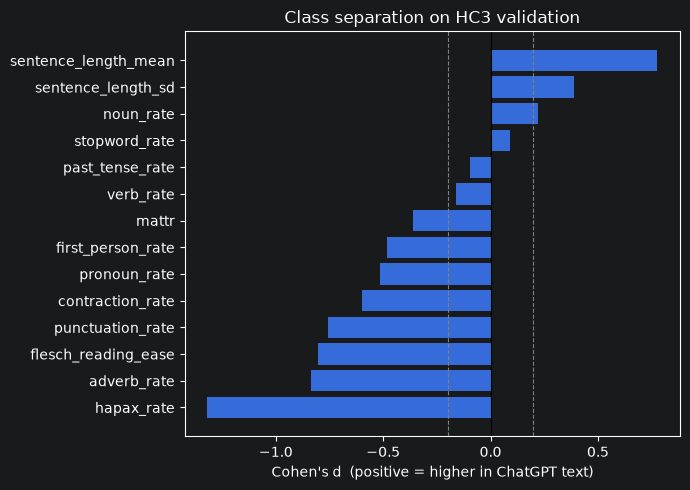

In [4]:
order = separation.sort_values("d").index
plt.figure(figsize=(7, 5))
plt.barh(order, separation.loc[order, "d"])
plt.axvline(0, color="black", linewidth=0.8)
for edge in (-0.2, 0.2):
    plt.axvline(edge, color="grey", linestyle="--", linewidth=0.8)
plt.xlabel("Cohen's d  (positive = higher in ChatGPT text)")
plt.title("Class separation on HC3 validation")
plt.tight_layout()
plt.show()

Features inside the dashed lines have little effect on HC3. That is not on
its own a reason to cut one, since HC3 has a single generator and MAGE has 27,
but a feature that is flat here and flat on MAGE is carrying no signal and is
only adding noise to the SHAP analysis.

## 3. Does any feature measure length?

This is the check that matters most, because §3.2 takes length out deliberately
and §3.6 claims the detector does not use it. Spearman correlation is used
rather than Pearson, since text lengths are heavily skewed and Flesch reading
ease is on a different scale from the rest.

A correlation above about 0.3 in absolute value means a feature is carrying a
noticeable amount of length, which needs saying in §3.6. Above 0.5 and the
feature is partly a length measure and should be reconsidered.

In [5]:
with_length = (
    features[FEATURE_NAMES + ["words"]]
    .corr(method="spearman")["words"]
    .drop("words")
    .sort_values()
)

print("correlation with text length, worst first:")
print(with_length.reindex(with_length.abs().sort_values(ascending=False).index).round(3))

correlation with text length, worst first:
hapax_rate             -0.749
sentence_length_sd      0.573
sentence_length_mean    0.452
flesch_reading_ease    -0.292
mattr                  -0.191
punctuation_rate       -0.186
pronoun_rate           -0.140
adverb_rate            -0.133
verb_rate              -0.085
stopword_rate           0.061
noun_rate               0.052
past_tense_rate         0.037
first_person_rate       0.026
contraction_rate       -0.013
Name: words, dtype: float64


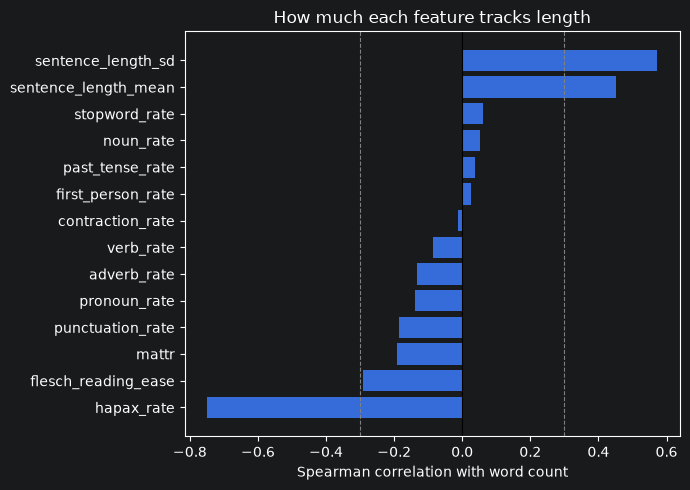

In [6]:
order = with_length.index
plt.figure(figsize=(7, 5))
plt.barh(order, with_length.loc[order])
plt.axvline(0, color="black", linewidth=0.8)
for edge in (-0.3, 0.3):
    plt.axvline(edge, color="grey", linestyle="--", linewidth=0.8)
plt.xlabel("Spearman correlation with word count")
plt.title("How much each feature tracks length")
plt.tight_layout()
plt.show()

Two features are expected to show something here. Hapax rate keeps a known
length sensitivity, which was accepted because the length-robust alternative
duplicates MATTR. Sentence-length mean and standard deviation are measures of
sentence length rather than text length, so they need not be flat, but a strong
correlation would mean longer texts also have longer sentences, which is worth
knowing.

MATTR should be close to zero. If it is not, the moving window has not done its
job and the whole argument for using it instead of the plain type-token ratio
falls over.

### What survives when lengths are matched

ChatGPT answers are longer than human ones, so some of the separation above may
be length rather than writing. The training split pairs each ChatGPT answer with
a human answer of roughly the same length, which takes length out. Running the
same comparison there shows what is left.

In [7]:
from logos.project_data.preprocess import length_match

# The training split pairs each ChatGPT answer with a human answer of
# roughly the same length. So in here, length can't tell the classes apart.
train_df, _ = train_val_split(hc3, val_fraction=0.15)
train_df = length_match(train_df)

train_features = features_frame(train_df["text"].tolist(), show_progress=True)
train_labels = train_df["label"].to_numpy()

both = pd.DataFrame({
    "natural lengths": separation["d"],
    "lengths matched": [cohens_d(train_features[f].to_numpy(), train_labels)
                        for f in FEATURE_NAMES],
}, index=FEATURE_NAMES)

both["shrank by"] = both["natural lengths"].abs() - both["lengths matched"].abs()
both.sort_values("shrank by", ascending=False).round(3)

  1,000 of 7,788
  2,000 of 7,788
  3,000 of 7,788
  4,000 of 7,788
  5,000 of 7,788
  6,000 of 7,788
  7,000 of 7,788


,natural lengths,lengths matched,shrank by
hapax_rate,-1.319,-0.924,0.395
sentence_length_mean,0.777,0.435,0.342
flesch_reading_ease,-0.805,-0.467,0.338
sentence_length_sd,0.387,-0.090,0.297
noun_rate,0.221,0.010,0.210
pronoun_rate,-0.515,-0.366,0.149
verb_rate,-0.159,0.103,0.055
first_person_rate,-0.480,-0.457,0.023
contraction_rate,-0.597,-0.600,-0.003
adverb_rate,-0.837,-0.858,-0.021


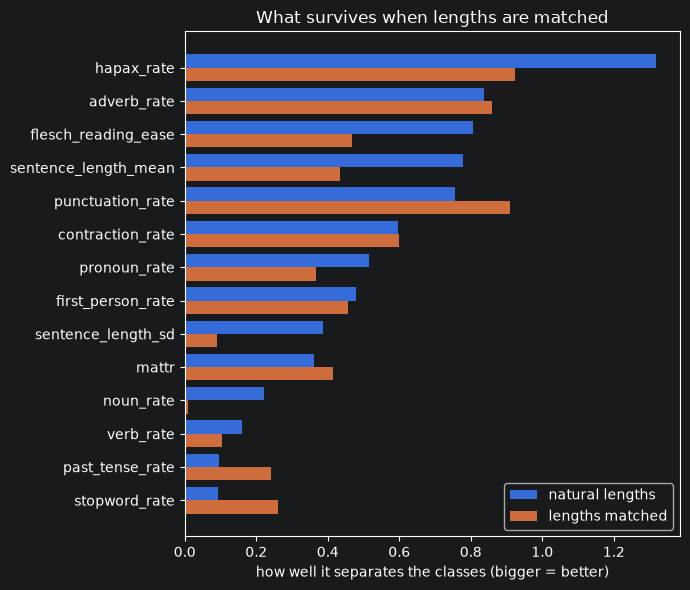

In [8]:
# Same features, two bars each. Short bar next to a long one = that feature
# was partly just measuring how long the text is.
order = both["natural lengths"].abs().sort_values().index
y = np.arange(len(order))

plt.figure(figsize=(7, 6))
plt.barh(y + 0.2, both.loc[order, "natural lengths"].abs(), height=0.4, label="natural lengths")
plt.barh(y - 0.2, both.loc[order, "lengths matched"].abs(), height=0.4, label="lengths matched")
plt.yticks(y, order)
plt.xlabel("how well it separates the classes (bigger = better)")
plt.title("What survives when lengths are matched")
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
# Desaire et al. measure sentence-length deviation inside each paragraph. Check
# whether paragraph boundaries survive the normalisation, so section 3.6 can say
# whether their version is reproducible here.
share = val_df["text"].str.contains("\n").mean()
print(f"{share:.1%} of validation texts contain a line break")

0.0% of validation texts contain a line break


## 4. How much do the features duplicate each other?

Three pairs overlap by construction. Past tense is a subset of verb, first
person is a subset of pronoun, and Flesch reading ease contains mean sentence
length as one of its two terms. The question is how large those correlations are
in practice, and whether any unplanned duplication has crept in.

This matters for RQ3 rather than for prediction. A neural model is happy with
correlated inputs, but SHAP splits credit between them in a way that can move
between runs, which adds noise to the per-family importance vectors that U_k is
computed from (§3.5).

In [10]:
correlations = features[FEATURE_NAMES].corr(method="spearman")

# Every pair once, strongest first. The dropna matters: pandas 3 no longer
# drops missing values in stack(), so without it the masked-out half of the
# matrix comes through as NaN and there are 196 rows instead of 91
pairs = (
    correlations.where(np.triu(np.ones(correlations.shape), k=1).astype(bool))
    .stack()
    .dropna()
    .rename("spearman")
    .reset_index()
    .rename(columns={"level_0": "feature_a", "level_1": "feature_b"})
)
pairs["abs"] = pairs["spearman"].abs()
print(f"{len(pairs)} feature pairs")

print("pairs above 0.7, which is where duplication starts to matter:")
print(pairs[pairs["abs"] > 0.7].sort_values("abs", ascending=False).round(3).to_string(index=False))

91 feature pairs
pairs above 0.7, which is where duplication starts to matter:
Empty DataFrame
Columns: [feature_a, feature_b, spearman, abs]
Index: []


In [11]:
# The three overlaps that were predicted, named explicitly so they can be
# reported rather than rediscovered
expected = [
    ("past_tense_rate", "verb_rate"),
    ("first_person_rate", "pronoun_rate"),
    ("flesch_reading_ease", "sentence_length_mean"),
]
for a, b in expected:
    print(f"{a:22s} vs {b:22s} {correlations.loc[a, b]:+.3f}")

past_tense_rate        vs verb_rate              +0.218
first_person_rate      vs pronoun_rate           +0.382
flesch_reading_ease    vs sentence_length_mean   -0.621


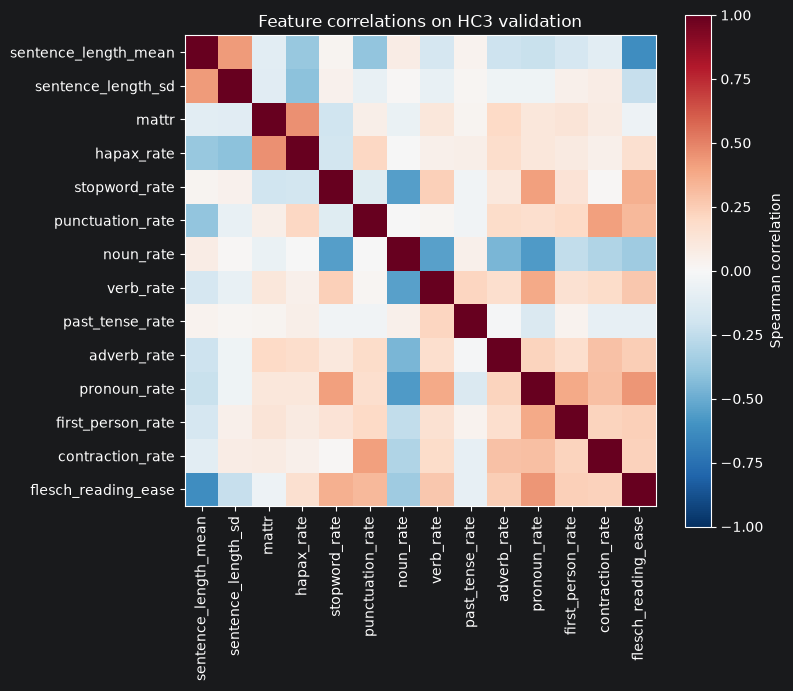

In [12]:
plt.figure(figsize=(8, 7))
plt.imshow(correlations, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="Spearman correlation")
plt.xticks(range(len(FEATURE_NAMES)), FEATURE_NAMES, rotation=90)
plt.yticks(range(len(FEATURE_NAMES)), FEATURE_NAMES)
plt.title("Feature correlations on HC3 validation")
plt.tight_layout()
plt.show()

## 5. Does MATTR have enough spread at a 25-word window?

Appendix D records why the window is 25 rather than larger. A bigger window
gives more spread, but more texts fall below it and drop to the plain
type-token ratio, which is the length-dependent measure MATTR exists to avoid.

In [13]:
from nltk.tokenize import word_tokenize

from logos.features.stylometric import mattr, words_in

sample = val_df.sample(2000, random_state=0)

tokenised = [
    [word.lower() for word in words_in(word_tokenize(text))]
    for text in sample["text"]
]

for window in (25, 50):
    values = np.array([mattr(words, window=window) for words in tokenised])
    below = np.mean([len(words) <= window for words in tokenised])
    print(f"window {window:3d}   mean {values.mean():.3f}   sd {values.std(ddof=1):.3f}"
          f"   below window {below:.1%}")

window  25   mean 0.877   sd 0.052   below window 9.4%
window  50   mean 0.790   sd 0.079   below window 23.2%


## 6. Save

The features are saved so the checks above can be repeated without recomputing,
and so the figures quoted in §3.6 and Appendix D have a source.

In [14]:
out_path = DATA_DIR / "hc3" / "features" / "stylometric.parquet"
out_path.parent.mkdir(parents=True, exist_ok=True)
features.to_parquet(out_path, index=False)

print(f"saved {len(features)} rows to {out_path}")

saved 11708 rows to /Users/xwm517/Desktop/logos/data/hc3/features/stylometric.parquet


In [16]:
# The table to be reported as Table D.3 in Appendix D.
print(pd.DataFrame({
    "d": separation["d"],
    "r_with_length": with_length,
}).round(3).to_markdown())

|                      |      d |   r_with_length |
|:---------------------|-------:|----------------:|
| adverb_rate          | -0.837 |          -0.133 |
| contraction_rate     | -0.597 |          -0.013 |
| first_person_rate    | -0.48  |           0.026 |
| flesch_reading_ease  | -0.805 |          -0.292 |
| hapax_rate           | -1.319 |          -0.749 |
| mattr                | -0.36  |          -0.191 |
| noun_rate            |  0.221 |           0.052 |
| past_tense_rate      | -0.097 |           0.037 |
| pronoun_rate         | -0.515 |          -0.14  |
| punctuation_rate     | -0.756 |          -0.186 |
| sentence_length_mean |  0.777 |           0.452 |
| sentence_length_sd   |  0.387 |           0.573 |
| stopword_rate        |  0.092 |           0.061 |
| verb_rate            | -0.159 |          -0.085 |


## Observations

### The features separate the classes

Seven of the fourteen reach a Cohen's d of 0.5 or more. The strongest are hapax
rate (-1.32), adverb rate (-0.84), Flesch reading ease (-0.81), mean sentence
length (+0.78) and punctuation rate (-0.76).

All seven describe one picture. ChatGPT text uses a narrower vocabulary, fewer
adverbs and pronouns, longer sentences, less punctuation, fewer contractions,
almost no first person, and scores lower on reading ease. That is the
formal-versus-conversational split notebook 02 found in the TF-IDF weights,
measured directly this time.

Three do almost nothing on HC3: stop-word rate (0.09), past tense (0.10) and
verb rate (0.16).

### How much of this is length?

ChatGPT answers are longer (median 174 words against 74), so some of the
separation above could be length rather than writing. Repeating the comparison
on the length-matched training split separates the two. The `shrank by` column
is the difference, and a negative value means the feature got stronger once
lengths were equal.

One feature is genuinely length. Sentence-length deviation correlates +0.573
with word count and loses all of its separation, from +0.387 to -0.090.

Two more are part length and part writing. Mean sentence length falls from
+0.777 to +0.435, and Flesch reading ease from -0.805 to -0.467. Both keep
about half their separation, so both carry a real signal on top of length.
Flesch doing this is expected, since mean sentence length is one of its two
terms.

Two collapse for a different reason. Noun rate falls from +0.221 to +0.010 and
verb rate flips from -0.159 to +0.103, but their length correlations are
negligible at +0.052 and -0.085. They are simply weak on a single-generator
corpus, not length artefacts.

Hapax rate is the opposite case. It carries the highest length correlation in
the set at -0.749, and still falls only from -1.319 to -0.924, staying the
strongest feature by a distance. That correlation accompanies a real signal
rather than replacing it.

Six features get stronger once length is removed, most clearly stop-word rate
(0.092 to 0.260), punctuation rate (0.756 to 0.910), past tense (0.097 to
0.240) and MATTR (0.360 to 0.415). Length was masking them.

### The features do not duplicate each other

No pair correlates above 0.7, out of 91 pairs. Of the three overlaps expected by
construction, only Flesch against mean sentence length is notable at -0.621;
past tense against verb rate is +0.218 and first person against pronoun rate is
+0.382. The SHAP analysis in section 3.5 therefore has less redundancy to
contend with than the construction of the features suggested.

### MATTR's window

Covington and McFall's MATTR of about 2 x W^-0.2 predicts a value above 1.0 for
any window below about 32, which would mean the measure saturates at 25 and
cannot discriminate. It does not. At 25 the mean is 0.877 with a standard
deviation of 0.052, and MATTR's length correlation of -0.191 shows the moving
window did its job.

Raising the window to 50 improves the spread to 0.079 but sends 23.2% of HC3
texts below the window, against 9.4% at 25. A text below the window drops to the
plain type-token ratio, which is the length-dependent measure MATTR exists to
avoid, so the smallest window with usable spread is the right one.

### Carried forward

- All 14 features are kept. HC3 has one generator and MAGE has 27 across seven
  families, so a feature flat on ChatGPT need not be flat on GPT-J.
- Training pairs are length-matched in every MAGE condition, so length cannot
  produce separation in the trained detector. The design already handles it.
- Hapax rate's length sensitivity is reported in section 3.6, along with
  sentence-length deviation being length rather than style.